# Justificativas para limpeza de dados

Limpeza implementada em src/data_cleaning.py.

---
## Contexto

### Objetivo do projeto

--

### O dataset

O conjunto de dados contém informações sobre cursos de ensino superior da Universidade Federal do Paraná (UFPR). Cada linha possui informações de um curso em um determinado ano. Após o carregamento dos dados (src/data_loading.py), as colunas são

`curso`, `setor`, `campus`, `grau`, `turno`, `ano`, `vagas_ps`, `inscritos_ps`, `aprovados_ps`, `ingressantes_ps`, `rel_cand_vaga`, `vagas_sisu`, `ingressantes_sisu`, `ingressantes_provar`, `ingressantes_outros`, `matriculados`, `evadidos` e `concluintes`

Como não existe id, consideramos que, em conjunto, as colunas curso, campus, grau e turno definem cada curso. Idealmente, um ano deve possuir no máximo uma instância de cada curso

Na fonte, os dados disponibilizados pela UFPR são separados por ano, portanto foi necessário corrigir, transformar e concatenar os CSVs para um carregamento de dados bem sucedido. Foi escolhido o período de 2018 à 2025.

**Fonte**: [Quantitativo de Alunos de Graduação](https://ufpr.br/transparencia/quantitativo-de-alunos-de-graduacao/)

---
## Configuração do ambiente

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from IPython.display import display, display_html

import data_loading as dl
import data_cleaning as dc

df = dl.load_data()

---
## Visão geral do dataset bruto

In [2]:
df.shape

(1327, 18)

In [3]:
df.dtypes

curso                     str
setor                     str
campus                    str
grau                      str
turno                     str
ano                     int64
vagas_ps               object
inscritos_ps           object
aprovados_ps           object
ingressantes_ps        object
rel_cand_vaga          object
vagas_sisu             object
ingressantes_sisu      object
ingressantes_provar    object
ingressantes_outros    object
matriculados           object
evadidos               object
concluintes            object
dtype: object

In [4]:
df.sample(3, random_state=42)

,curso,setor,campus,grau,turno,ano,vagas_ps,inscritos_ps,aprovados_ps,ingressantes_ps,rel_cand_vaga,vagas_sisu,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
890,Engenharia Elétrica,Setor de Tecnologia,Campus Centro Politécnico,Bacharelado,I,2020,80,307,104,88,"3,79",20,21,0,8,"239,50",34,62
115,Gestão de Turismo,Litoral,Campus Litoral (Matinhos),Tecnológico,N,2018,28,0,28,26,"0,00",7,2,2,0,95,26,11
543,Geografia,Setor de Ciências da Terra,Campus Centro Politécnico,Licenciatura,N,2023,32,39,30,0,1.18,8,0,0,0,75.0,27,17


In [5]:
df.describe(exclude='str')

,ano,vagas_ps,inscritos_ps,aprovados_ps,ingressantes_ps,rel_cand_vaga,vagas_sisu,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
count,1327.000000,1327.0,1327.0,1327.0,1326.0,1327,1327.0,1326.0,1326.0,1326.0,1326.0,1326.0,1326.0
unique,NaN,111.0,484.0,233.0,216.0,595,75.0,69.0,25.0,80.0,799.0,176.0,173.0
top,NaN,0.0,0.0,0.0,0.0,"0,00",0.0,0.0,0.0,0.0,0.0,0.0,0.0
freq,NaN,128.0,249.0,132.0,272.0,177,163.0,353.0,757.0,392.0,33.0,63.0,130.0
mean,2021.787491,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,2.279503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,2018.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2020.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2022.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2024.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
cat_names = lambda col: pd.Series(df[col].value_counts().index)
pd.DataFrame({
    'Setores': cat_names('setor'),
    'Campi': cat_names('campus'),
    'Graus': pd.concat([cat_names('grau')[:21], pd.Series(['⋮'])], ignore_index=True),
    'Turnos': cat_names('turno')
}).fillna('').style.hide(axis='index')

Setores,Campi,Graus,Turnos
Setor de Ciências Humanas,Campus Centro Politécnico,Bacharelado,N
Setor de Ciências Exatas,Campus Centro - Reitoria,Licenciatura,I
Setor Palotina,Campus Litoral (Matinhos),Múltiplo,M
Setor Litoral,Campus Palotina,Tecnológico,T
Setor de Tecnologia,Campus Jardim Botânico,Segunda Licenciatura,EaD
Jandaia,Campus Jandaia do Sul,Ciências Exatas,E
Setor de Educação Profissional e Tecnológica,SEPT,Licenciatura (Física),
Setor de Ciências Biológicas,Campus Juvevê (SACOD),Licenciatura (Matemática),
"Setor de Artes, Comunicação e Design",Campus Centro - Saúde,Licenciatura (Química),
Setor de Ciências da Saúde,Campus Pontal do Paraná,Ciências Biológicas,


---
## Resumo de decisões

In [7]:
_, rows_affected, cols_affected = dc.clean_data(df.copy())

tb = pd.DataFrame({
    'Decisão': [
        'Substituir \\N por valor nulo e vírgula por ponto.',
        'Deletar as colunas vagas_ps, inscritos_ps, aprovados_ps, rel_cand_vaga e vagas_sisu.',
        'Deletar todas as linhas com valores nulos.',
        'Eliminar redundâncias do nome dos cursos e simplificar cursos de Letras.',
        'Eliminar redundância e padronizar setores, renomear Jandaia, Litoral e Palotina para Desconhecido e Toledo para Ciências da Saúde.',
        'Eliminar redundância da coluna campus.',
        'Renomear curso para Matemática aqueles em que o grau é Licenciatura (Matemática). Fazer o mesmo para Licenciatura (Física) e Licenciatura (Química), simplificando para Licenciatura e os graus inválidos para Desconhecido.',
        'Deletar cursos que estão ausentes em algum ano.',
        'Eliminar duplicatas idênticas ou que parecem incompletas.'
    ],
    'Linhas afetadas': rows_affected,
    'Colunas afetadas': cols_affected
})

tb.index = range(1, len(rows_affected)+1)
tb.style \
    .set_properties(**{'text-align': 'left'}) \
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'left')]}
    ])

,Decisão,Linhas afetadas,Colunas afetadas
1,Substituir \N por valor nulo e vírgula por ponto.,840,12
2,"Deletar as colunas vagas_ps, inscritos_ps, aprovados_ps, rel_cand_vaga e vagas_sisu.",0,5
3,Deletar todas as linhas com valores nulos.,8,0
4,Eliminar redundâncias do nome dos cursos e simplificar cursos de Letras.,83,1
5,"Eliminar redundância e padronizar setores, renomear Jandaia, Litoral e Palotina para Desconhecido e Toledo para Ciências da Saúde.",1319,1
6,Eliminar redundância da coluna campus.,1236,1
7,"Renomear curso para Matemática aqueles em que o grau é Licenciatura (Matemática). Fazer o mesmo para Licenciatura (Física) e Licenciatura (Química), simplificando para Licenciatura e os graus inválidos para Desconhecido.",247,2
8,Deletar cursos que estão ausentes em algum ano.,85,0
9,Eliminar duplicatas idênticas ou que parecem incompletas.,34,0


---
## Evidências e justificativas

### 1. Valores inválidos e parsing de colunas

- As colunas númericas apresentam o caractere \N e números decimais com vírgula (strings). Valores inválidos causam erros no parsing de colunas.

In [8]:
def not_is_num(num):
    try:
        float(num)
        return False
    except ValueError:
        return True

invalids = []
for col_name in dc.num_cols:
    counts_idx = df[col_name].value_counts().index
    not_is_num_list = list(map(not_is_num, counts_idx))
    invalids.append(list(counts_idx[not_is_num_list])[:5])

pd.DataFrame({
    'Coluna': dc.num_cols,
    'Exemplos de valores inválidos': invalids
}).style.hide(axis='index')

Coluna,Exemplos de valores inválidos
ano,[]
vagas_ps,['\\N']
inscritos_ps,['\\N']
aprovados_ps,['\\N']
ingressantes_ps,['\\N']
vagas_sisu,['\\N']
ingressantes_sisu,['\\N']
ingressantes_provar,['\\N']
ingressantes_outros,['\\N']
matriculados,"['0,00', '\\N', '21,00', '60,00', '121,50']"


##### **Decisão**: Substituir \N por valor nulo, vírgula por ponto e fazer parsing adequado das colunas numéricas.

In [9]:
df, *_ = dc.fix_invalid_data(df)

### 2. Manipulação de colunas

- Há as seguintes regras esperadas entre colunas numéricas:
\begin{align*}
    \text{vagas\_ps} &\geq \text{ingressantes\_ps} \\
    \text{aprovados\_ps} &\geq \text{ingressantes\_ps} \\
    \text{inscritos\_ps} &\geq \text{aprovados\_ps} \\
    \text{vagas\_sisu} &\geq \text{ingressantes\_sisu}
\end{align*}
Entretanto, existem exceções para cada regra. As exceções da primeira regra cobrem 27% dos dados, enquanto as exceções das demais cobrem 8-9%. Essas taxas podem ser relevantes tendo em vista a baixa granularidade e tamanho do dataset.

- Em todas as exceções da terceira regra, inscritos_ps é igual a zero. As colunas vagas_ps, inscritos_ps, aprovados_ps, rel_cand_vaga e vagas_sisu não são relevantes para o objetivo do projeto.

Obs. 1: As exceções também podem incluir valores nulos, não necessariamente comparação numérica.

Obs. 2: As regras são suposições do autor deste projeto, pois não há nada diretamente a favor ou contra na documentação original dos dados com relação à elas. Uma possível ação, no caso de ter o contato dos responsáveis pelos dados, seria questionar sobre as aparentes inconsistências, investigando a existência de regras ocultas.

In [10]:
def pct_rule(col1, col2):
    quant = len(df[df[col1] < df[col2]])
    print(f"{f'{col1} < {col2}:':<33}{quant/len(df):.2f}")

pct_rule('vagas_ps', 'ingressantes_ps')
pct_rule('aprovados_ps', 'ingressantes_ps')
pct_rule('inscritos_ps', 'aprovados_ps')
pct_rule('vagas_sisu', 'ingressantes_sisu')

count_inscritos = len(df[(df['inscritos_ps'] < df['aprovados_ps']) & (df['inscritos_ps'] > 0)])
print(f'\n0 < inscritos_ps < aprovados_ps: {count_inscritos}')

vagas_ps < ingressantes_ps:      0.27
aprovados_ps < ingressantes_ps:  0.08
inscritos_ps < aprovados_ps:     0.09
vagas_sisu < ingressantes_sisu:  0.08

0 < inscritos_ps < aprovados_ps: 0


##### **Decisão**: Deletar as colunas vagas_ps, inscritos_ps, aprovados_ps, rel_cand_vaga e vagas_sisu.

In [11]:
df, *_ = dc.manipulates_cols(df)

### 3. Valores nulos

- Existem no total 8 linhas com valores nulos, 0,6% dos dados.

- O gráfica indica que os nulos compartilham as mesmas linhas. A proporção é muito baixa para investir tempo em investigação mais detalhada.



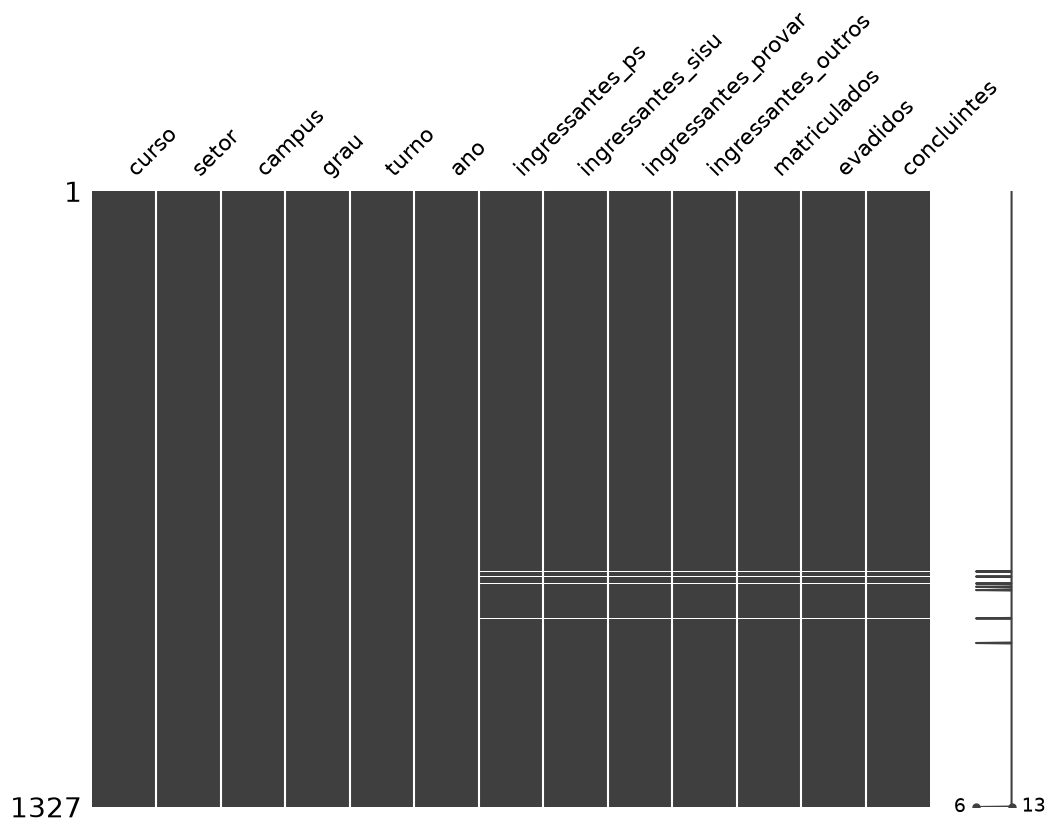


8 linhas com nulos, 0.006 dos dados


In [12]:
msno.matrix(df, figsize=(12, 8))
plt.show()

rows_with_na = df[df.columns].isna().any(axis=1).values
idxs_len = len(df.index[rows_with_na])
print(f'\n{idxs_len} linhas com nulos, {idxs_len/len(df):.2} dos dados')

##### **Decisão**: Deletar todas as linhas com valores nulos.

In [13]:
df, *_ = dc.drop_na(df)

### 4. Colunas categóricas

#### Coluna curso

- Existem cursos com informação de outra coluna no nome, como por exemplo "(Diurno)" e "- Bacharelado".

- Apesar de existir, por exemplo o curso "Letras - Polonês", existe um curso mais específico denominado "Letras - Português e Polonês". São cursos diferentes, mas tendo em vista o tamanho do dataset, tais divisões podem prejudicar a representatividade dos cursos de Letras.

In [14]:
cols = ['curso', 'grau', 'turno']

pd.concat([
    df.loc[df['curso'].str.endswith('(Diurno)'),            cols].head(1),
    df.loc[df['curso'].str.endswith('- Bacharelado'),       cols].head(1),
    df.loc[df['curso'] == 'Letras - Polonês',               cols].head(1),
    df.loc[df['curso'].str.endswith('Português e Polonês'), cols].head(1)
])

,curso,grau,turno
53,Filosofia (Diurno),Múltiplo,M
19,Educação Física - Bacharelado,Bacharelado,I
65,Letras - Polonês,Múltiplo,N
407,Letras - Português e Polonês,Licenciatura,N


##### **Decisão**: Eliminar informações extras no nome dos cursos e simplificar variedade dos cursos de Letras.

In [15]:
df, *_ = dc.clean_curso_names(df)

#### Coluna setor

- A maioria dos setores começa com "Setor", o que é redundante, além de pequenos erros de digitação como ponto no lugar de vírgula e palavras maiúsculas.

- Os "setores" Jandaia, Litoral e Palotina, são na verdade localizações de campus e estão distribuídas em vários cursos distintos, dificultando a identificação de um padrão para deduzir os reais setores de tais cursos. Já o "setor" Toledo, que também é uma localização, apresenta um padrão claro: todos os cursos associados são de Medicina, o que nos permite deduzir que seus setores corretos são Ciências da Saúde.

Obs.: Uma opção seria se reunir com algum responsável pelos dados a fim de corrigir os setores de maneira confiável.

In [16]:
se1 = df['setor'].value_counts()
se2 = df.loc[df['setor'] == 'Jandaia', 'curso'].value_counts()
se3 = df.loc[df['setor'] == 'Toledo', 'curso'].value_counts()
df1 = pd.DataFrame({'Setor': se1.index, 'Quant.': se1.values})
df2 = pd.DataFrame({'Curso com setor Jandaia': se2.index, 'Quant.': se2.values})
df3 = pd.DataFrame({'Curso com setor Toledo': se3.index, 'Quant.': se3.values})

display_html(
    f'<div style="display: flex; gap: 50px">'
    f'<div>{df1.to_html(index=False)}</div>'
    f'<div>{df2.to_html(index=False)} <br/><br/> {df3.to_html(index=False)}</div>'
    f'</div>',
    raw=True
)


Setor,Quant.
Setor de Ciências Humanas,248
Setor de Ciências Exatas,116
Setor Palotina,94
Setor Litoral,89
Setor de Tecnologia,80
Jandaia,78
Setor de Educação Profissional e Tecnológica,75
Setor de Ciências Biológicas,70
"Setor de Artes, Comunicação e Design",68
Setor de Ciências da Saúde,66


##### **Decisão**: Eliminar redundância e padronizar setores, renomear Jandaia, Litoral e Palotina para Desconhecido e Toledo para Ciências da Saúde.

In [17]:
df, *_ = dc.clean_setor_names(df)

#### Coluna campus

- A maioria dos campi começa com "Campus", o que é redundante.

In [18]:
se = df['campus'].value_counts()
dataf = pd.DataFrame({'Campus': se.index, 'Quant.': se.values})
dataf.style.hide(axis='index')

Campus,Quant.
Campus Centro Politécnico,321
Campus Centro - Reitoria,258
Campus Litoral (Matinhos),125
Campus Palotina,116
Campus Jardim Botânico,83
Campus Jandaia do Sul,78
SEPT,75
Campus Juvevê (SACOD),64
Campus Centro - Saúde,52
Campus Pontal do Paraná,48


##### **Decisão**: Eliminar redundância da coluna campus apagando "Campus" de seus nomes.

In [19]:
df, *_ = dc.clean_campus_names(df)

#### Coluna grau

- Todos os cursos nos quais o grau é Licenciatura (Matemática), Licenciatura (Física) ou Licenciatura (Química) são apenas um: Ciências Exatas. Portanto, interpreta-se que os verdadeiros cursos, nesses casos, constam em seus respectivos graus.

- As categorias para grau são Bacharelado, Licenciatura, Segunda Licenciatura, Múltiplo e Tecnológico. No entanto, nessa coluna estão presentes outros nomes, como por exemplo nome do curso.

In [20]:
degrees = ['Licenciatura (Matemática)', 'Licenciatura (Física)', 'Licenciatura (Química)']
se = df.loc[df['grau'].isin(degrees), 'curso'].value_counts()
cat_degrees = ['Bacharelado', 'Licenciatura', 'Segunda Licenciatura', 'Múltiplo', 'Tecnológico']

display(pd.DataFrame({
    'Curso que apresenta curso específico no grau': se.index,
    'Quant.': se.values
}).style.hide(axis='index'))

display(df.loc[~df['grau'].isin([
        'Bacharelado',
        'Licenciatura',
        'Segunda Licenciatura',
        'Múltiplo',
        'Tecnológico'
]), ['curso', 'grau']][45:50])

Curso que apresenta curso específico no grau,Quant.
Ciências Exatas,45


,curso,grau
642,Engenharia de Produção,Engenharia de Produção
643,Pedagogia,Pedagogia
644,Expressão Gráfica,Expressão Gráfica
645,Letras - Português,Letras - Português
646,Letras - Inglês,Letras - Inglês


##### **Decisão**: Renomear curso para Matemática aqueles em que o grau é Licenciatura (Matemática). Agir analogamente onde grau é igual a Licenciatura (Física) e Licenciatura (Química), renomeando esses graus para apenas Licenciatura e todos os demais para Desconhecido.

In [21]:
df, *_ = dc.clean_grau_names(df)

### 5. Representatividade de cursos por ano

- Alguns cursos não possuem instância em algum ano, isso pode prejudicar análises temporais.

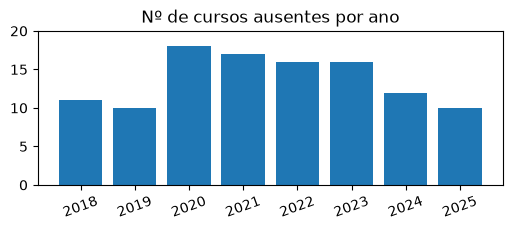

23 cursos ausentes em algum ano. Exemplos:

Engenharia de Energia
Gestão Cultural
Gestão Ambiental
Letras - Português, e/ou Alemão, e/ou Grego, e/ou Latim
Biocombustíveis


In [22]:
cats = df['curso'].value_counts().index
bad_cats = {}
curso_names = set()

for cat in cats:
    for year in range(2018, 2026):
        if len(df[(df['curso'] == cat) & (df['ano'] == year)]) == 0:
            curso_names.add(cat)
            try:
                bad_cats[year] += 1
            except KeyError:
                bad_cats[year] = 1

plt.figure(figsize=(6, 2))
plt.bar(bad_cats.keys(), bad_cats.values())
plt.title('Nº de cursos ausentes por ano')
plt.xticks(rotation=20)
plt.ylim(0, 20)
plt.show()

print(len(curso_names), 'cursos ausentes em algum ano. Exemplos:\n')
for i in range(5):
    print(list(curso_names)[i])

##### **Decisão**:  Deletar linhas de cursos que estão ausentes em algum ano.

In [23]:
df, *_ = dc.clean_missing_courses(df)

### 6. Cursos duplicados

- Lembre-se que as colunas curso, campus, grau e turno definem cada curso.

- Os cursos duplicados podem ser classificados em dois grupos: (1) linhas inteiras idênticas e (2) uma das linhas parece possuir as informações completas enquanto as demais parecem ser apenas parciais.

- Desconsideramos a categoria Desconhecido de grau por ser uma das colunas definidoras de um curso.

In [24]:
# Como os cursos devem ter apenas uma instância por ano, consideramos a sua coluna
cols = ['curso', 'campus', 'grau', 'turno', 'ano']
dupls = df.duplicated(subset=cols, keep=False)
no_desc = (df['grau'] != 'Desconhecido')

# Exemplos de cursos duplicados
exs = ['Administração', 'Física']

for course_name in exs:
    dupls_course = df[dupls & (df['curso'] == course_name) & no_desc]
    if len(dupls_course):
        display(dupls_course)

print('Total de duplicatas:', len(df[df.duplicated(subset=cols) & no_desc]))

,curso,setor,campus,grau,turno,ano,ingressantes_ps,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
1140,Administração,Ciências Sociais Aplicadas,Jardim Botânico,Bacharelado,N,2024,110,9,4,7,480,126,70
1141,Administração,Ciências Sociais Aplicadas,Jardim Botânico,Bacharelado,N,2024,110,9,4,7,480,126,70


,curso,setor,campus,grau,turno,ano,ingressantes_ps,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
43,Física,Ciências Exatas,Centro Politécnico,Licenciatura,N,2018,59,21,7,0,267,56,15
44,Física,Ciências Exatas,Centro Politécnico,Licenciatura,N,2018,0,0,0,0,11,0,11
240,Física,Ciências Exatas,Centro Politécnico,Licenciatura,N,2019,50,27,0,10,263,62,8
241,Física,Ciências Exatas,Centro Politécnico,Licenciatura,N,2019,0,0,0,0,0,0,0


Total de duplicatas: 34


##### **Decisão**: Eliminar duplicatas idênticas ou que parecem incompletas.

In [25]:
df, *_ = dc.del_duplicates(df)

---
## Visão geral do dataset limpo

In [26]:
df.shape

(1200, 13)

In [27]:
df.dtypes

curso                    str
setor                    str
campus                   str
grau                     str
turno                    str
ano                    Int64
ingressantes_ps        Int64
ingressantes_sisu      Int64
ingressantes_provar    Int64
ingressantes_outros    Int64
matriculados           Int64
evadidos               Int64
concluintes            Int64
dtype: object

In [28]:
df.sample(3, random_state=42)

,curso,setor,campus,grau,turno,ano,ingressantes_ps,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
1297,Terapia Ocupacional,Ciências da Saúde,Centro - Saúde,Bacharelado,N,2024,57,8,1,5,266,46,21
956,Pedagogia,Educação,Centro - Reitoria,Licenciatura,M,2020,59,13,0,7,347,7,50
110,Educação do Campo,Desconhecido,Litoral (Matinhos),Licenciatura,I,2018,33,0,0,0,207,17,47


In [29]:
df.describe()

,ano,ingressantes_ps,ingressantes_sisu,ingressantes_provar,ingressantes_outros,matriculados,evadidos,concluintes
count,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2021.81,29.55,6.445833,0.7725,4.811667,170.304167,25.995,21.713333
std,2.265284,33.04011,7.224419,2.003935,10.392041,179.699564,26.650801,26.896822
min,2018.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,2020.0,2.0,0.0,0.0,0.0,50.0,8.0,4.0
50%,2022.0,20.0,5.0,0.0,2.0,108.0,19.0,13.0
75%,2024.0,45.25,10.0,0.0,5.0,226.0,34.0,28.0
max,2025.0,242.0,49.0,18.0,196.0,1265.0,226.0,229.0


In [30]:
pd.DataFrame({
    'Setores': cat_names('setor'),
    'Campi': cat_names('campus'),
    'Graus': cat_names('grau'),
    'Turnos': cat_names('turno')
}).fillna('').style.hide(axis='index')

Setores,Campi,Graus,Turnos
Desconhecido,Centro Politécnico,Bacharelado,N
Ciências Humanas,Centro - Reitoria,Licenciatura,I
Ciências Exatas,Litoral (Matinhos),Desconhecido,M
Tecnologia,Palotina,Múltiplo,T
Ciências da Saúde,Jardim Botânico,Tecnológico,EaD
"Artes, Comunicação e Design",SEPT,Segunda Licenciatura,
Educação Profissional e Tecnológica,Jandaia do Sul,,
Ciências Biológicas,Juvevê (SACOD),,
Ciências da Terra,Centro - Saúde,,
Ciências Agrárias,Pontal do Paraná,,
